In [1]:
import pandas as pd

jobs = pd.read_csv("linkedin_job_postings.csv")

print("Rows and columns:", jobs.shape)
print("Columns:", jobs.columns.tolist())
print(jobs["job_level"].value_counts(dropna=False)
      if "job_level" in jobs.columns
      else "job_level column not found")

Rows and columns: (1348454, 14)
Columns: ['job_link', 'last_processed_time', 'got_summary', 'got_ner', 'is_being_worked', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type']
job_level
Mid senior    1204445
Associate      144009
Name: count, dtype: int64


In [2]:
# Select only the columns needed for Assignment 2
jobs_small = jobs[
    ["job_link", "job_title", "search_country", "job_level"]
].copy()

# Export the smaller dataset
jobs_small.to_csv(
    "linkedin_jobs_small.csv",
    index=False
)

print("File created successfully!")
print("Rows:", len(jobs_small))
print("Columns:", jobs_small.columns.tolist())

File created successfully!
Rows: 1348454
Columns: ['job_link', 'job_title', 'search_country', 'job_level']


In [3]:
import pandas as pd

# Load cleaned Skills & Competencies dataset
skills = pd.read_csv("skills_competencies_cleaned.csv")

# Select the job IDs used in your previous analysis
ba_job_links = set(skills["job_link"].dropna())

# Keep only matching BA-related jobs
ba_jobs_small = jobs[
    jobs["job_link"].isin(ba_job_links)
][["job_link", "job_title", "search_country", "job_level"]].copy()

# Remove duplicate job links
ba_jobs_small = ba_jobs_small.drop_duplicates(subset=["job_link"])

# Export the smaller dataset
ba_jobs_small.to_csv(
    "ba_jobs_for_assignment2.csv",
    index=False
)

print("BA jobs:", len(ba_jobs_small))
print("Columns:", ba_jobs_small.columns.tolist())
print("Job levels:")
print(ba_jobs_small["job_level"].value_counts(dropna=False))

BA jobs: 5000
Columns: ['job_link', 'job_title', 'search_country', 'job_level']
Job levels:
job_level
Mid senior    4389
Associate      611
Name: count, dtype: int64


In [4]:
print("BA jobs:", len(ba_jobs_small))
print("Job levels:")
print(ba_jobs_small["job_level"].value_counts(dropna=False))
print("File saved: ba_jobs_for_assignment2.csv")

BA jobs: 5000
Job levels:
job_level
Mid senior    4389
Associate      611
Name: count, dtype: int64
File saved: ba_jobs_for_assignment2.csv


In [5]:
import zipfile

with zipfile.ZipFile(
    "ba_jobs_for_assignment2.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    z.write("ba_jobs_for_assignment2.csv")

print("ZIP file created successfully!")

ZIP file created successfully!


In [6]:
import pandas as pd

skills = pd.read_csv("skills_competencies_cleaned.csv")

print("Rows and columns:", skills.shape)
print("\nColumns:")
print(skills.columns.tolist())

print("\nFirst 5 rows:")
display(skills.head())

print("\nMissing values:")
print(skills.isna().sum())

Rows and columns: (125294, 6)

Columns:
['job_link', 'job_title', 'skill_name', 'skill_clean', 'skill_standard', 'skill_category']

First 5 rows:


,job_link,job_title,skill_name,skill_clean,skill_standard,skill_category
0,https://www.linkedin.com/jobs/view/secret-clea...,Secret cleared Business Analyst,Microsoft Office 365,microsoft office 365,microsoft office 365,Unclassified
1,https://www.linkedin.com/jobs/view/secret-clea...,Secret cleared Business Analyst,Microsoft Teams,microsoft teams,microsoft teams,Unclassified
2,https://www.linkedin.com/jobs/view/secret-clea...,Secret cleared Business Analyst,SharePoint Online,sharepoint online,sharepoint online,Unclassified
3,https://www.linkedin.com/jobs/view/secret-clea...,Secret cleared Business Analyst,SharePoint 2016/2019,sharepoint 2016/2019,sharepoint 2016/2019,Unclassified
4,https://www.linkedin.com/jobs/view/secret-clea...,Secret cleared Business Analyst,Microsoft PowerPoint,microsoft powerpoint,microsoft powerpoint,Unclassified



Missing values:
job_link          0
job_title         0
skill_name        0
skill_clean       0
skill_standard    0
skill_category    0
dtype: int64


In [7]:
# Step 1: Load BA job information
ba_jobs = pd.read_csv("ba_jobs_for_assignment2.csv")

# Step 2: Check job-level data
print("BA jobs:", len(ba_jobs))
print("Unique job links:", ba_jobs["job_link"].nunique())
print("\nJob levels:")
print(ba_jobs["job_level"].value_counts(dropna=False))

# Step 3: Merge with cleaned skills
merged = skills.merge(
    ba_jobs[["job_link", "job_level"]],
    on="job_link",
    how="left",
    validate="many_to_one"
)

# Step 4: Check the merge
print("\nMerged rows:", len(merged))
print("Missing job levels:", merged["job_level"].isna().sum())
print("Unique jobs:", merged["job_link"].nunique())

BA jobs: 5000
Unique job links: 5000

Job levels:
job_level
Mid senior    4389
Associate      611
Name: count, dtype: int64

Merged rows: 125294
Missing job levels: 0
Unique jobs: 5000


Skills by Job Level (% of jobs in each level):


job_level,Associate,Mid senior
skill_standard,,
communication,49.59,49.92
project management,34.53,35.66
business analysis,37.48,34.29
problem solving,29.79,34.61
data analysis,27.00,33.95
teamwork,22.42,26.82
sql,20.13,26.52
requirements gathering,24.22,20.37
analytical skills,16.53,20.71


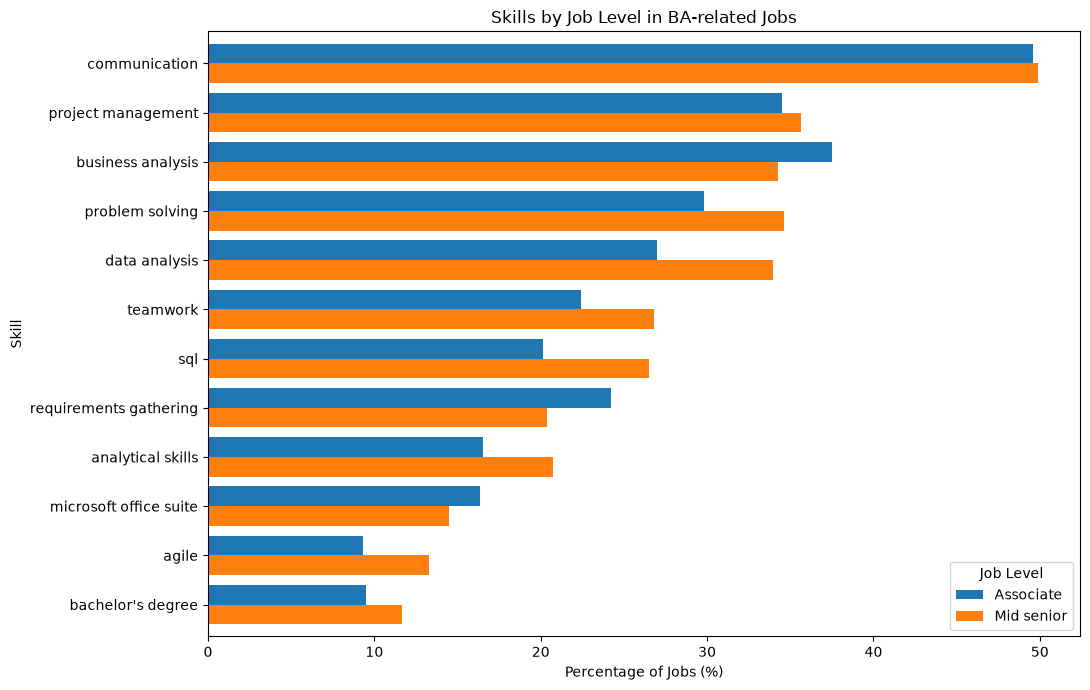

Saved: skills_by_job_level.png
Saved: skills_by_job_level.csv


In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Count unique jobs requiring each skill by job level
skill_level_counts = (
    merged[["job_link", "job_level", "skill_standard"]]
    .drop_duplicates()
    .groupby(["skill_standard", "job_level"])["job_link"]
    .nunique()
    .unstack(fill_value=0)
)

# Step 2: Calculate percentage within each job level
level_totals = ba_jobs["job_level"].value_counts()

skill_level_pct = (
    skill_level_counts
    .div(level_totals, axis=1)
    * 100
)

# Step 3: Select the 12 most common skills overall
top_skills = (
    merged.groupby("skill_standard")["job_link"]
    .nunique()
    .sort_values(ascending=False)
    .head(12)
    .index
)

comparison = skill_level_pct.loc[top_skills].copy()

# Step 4: Display the results
print("Skills by Job Level (% of jobs in each level):")
display(comparison.round(2))

# Step 5: Create comparison chart
ax = comparison.plot(
    kind="barh",
    figsize=(11, 7),
    width=0.8
)

ax.set_title("Skills by Job Level in BA-related Jobs")
ax.set_xlabel("Percentage of Jobs (%)")
ax.set_ylabel("Skill")
ax.legend(title="Job Level")

plt.gca().invert_yaxis()
plt.tight_layout()

# Step 6: Save chart and table
plt.savefig(
    "skills_by_job_level.png",
    dpi=300,
    bbox_inches="tight"
)

comparison.round(2).to_csv(
    "skills_by_job_level.csv"
)

plt.show()

print("Saved: skills_by_job_level.png")
print("Saved: skills_by_job_level.csv")


Top 15 skill pairs:


,Skill A,Skill B,Jobs Together,Percentage of Jobs
2,communication,problem solving,1328,26.56
0,communication,project management,1131,22.62
1,communication,business analysis,978,19.56
3,communication,data analysis,973,19.46
4,communication,teamwork,965,19.30
40,problem solving,teamwork,805,16.10
14,project management,business analysis,774,15.48
15,project management,problem solving,763,15.26
39,problem solving,data analysis,752,15.04
7,communication,analytical skills,686,13.72


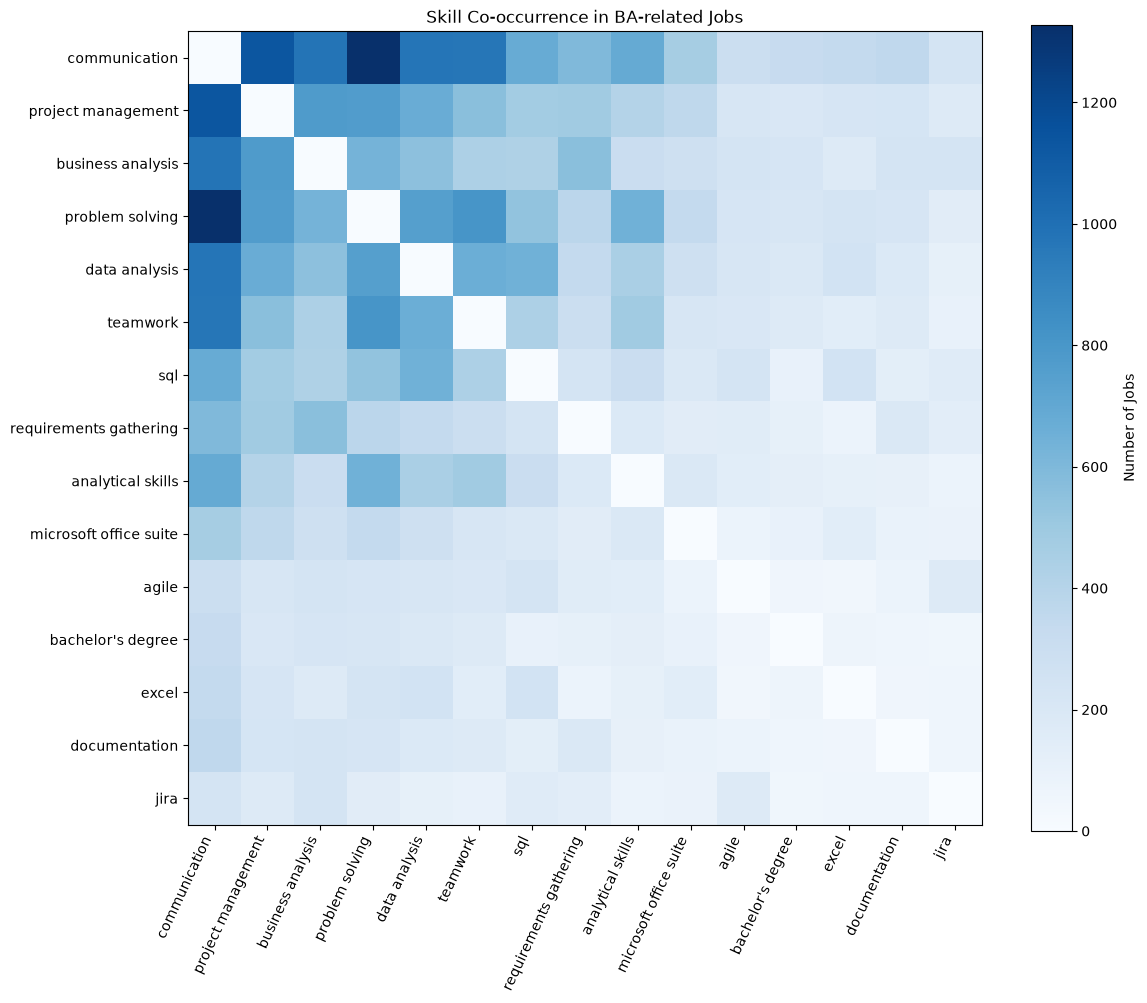

Saved: skill_cooccurrence_heatmap.png
Saved: skill_cooccurrence_pairs.csv


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

# Step 1: Select the 15 most common skills
top15 = (
    merged.groupby("skill_standard")["job_link"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .index
    .tolist()
)

# Step 2: Keep unique job-skill combinations
job_skills_top = (
    merged[merged["skill_standard"].isin(top15)]
    [["job_link", "skill_standard"]]
    .drop_duplicates()
)

# Step 3: Build a job-by-skill presence matrix
presence = pd.crosstab(
    job_skills_top["job_link"],
    job_skills_top["skill_standard"]
).gt(0).astype(int)

# Include all 5,000 jobs, even if none has a top-15 skill
presence = presence.reindex(
    index=ba_jobs["job_link"],
    columns=top15,
    fill_value=0
)

# Step 4: Count jobs containing each skill pair
pair_counts = presence.T.dot(presence)

# Remove self-pairs
for skill in top15:
    pair_counts.loc[skill, skill] = 0

# Step 5: Create a table of unique skill pairs
pairs = []

for skill_a, skill_b in combinations(top15, 2):
    count = int(pair_counts.loc[skill_a, skill_b])
    pairs.append({
        "Skill A": skill_a,
        "Skill B": skill_b,
        "Jobs Together": count,
        "Percentage of Jobs": round(count / len(ba_jobs) * 100, 2)
    })

pairs_df = (
    pd.DataFrame(pairs)
    .sort_values("Jobs Together", ascending=False)
)

print("Top 15 skill pairs:")
display(pairs_df.head(15))

# Step 6: Generate a heatmap
fig, ax = plt.subplots(figsize=(12, 10))

heatmap = ax.imshow(
    pair_counts.loc[top15, top15].to_numpy(),
    cmap="Blues"
)

ax.set_xticks(range(len(top15)))
ax.set_yticks(range(len(top15)))

ax.set_xticklabels(top15, rotation=65, ha="right")
ax.set_yticklabels(top15)

ax.set_title("Skill Co-occurrence in BA-related Jobs")

fig.colorbar(
    heatmap,
    ax=ax,
    label="Number of Jobs"
)

plt.tight_layout()

# Step 7: Save results
fig.savefig(
    "skill_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

pairs_df.to_csv(
    "skill_cooccurrence_pairs.csv",
    index=False
)

plt.show()

print("Saved: skill_cooccurrence_heatmap.png")
print("Saved: skill_cooccurrence_pairs.csv")


In [10]:

# Check the most common job titles
title_counts = (
    ba_jobs["job_title"]
    .value_counts()
    .head(30)
)

print("Top 30 Job Titles:")
display(title_counts)

print("\nTotal unique job titles:")
print(ba_jobs["job_title"].nunique())


Top 30 Job Titles:


job_title
Business Analyst                                        750
JDE Business Analyst (Supply Chain)                     156
Business Systems Analyst                                142
JD Edwards Business Analyst                             141
Senior Business Analyst                                 134
Business System Analyst                                  53
IT Business Analyst                                      53
Business Analyst II                                      47
Technical Business Analyst                               42
Senior Business Systems Analyst                          38
Business Analyst III                                     36
Business Process Analyst                                 30
Business Analyst I                                       28
Sr. Business Analyst                                     25
Salesforce Business Analyst                              20
Guidewire Business Analyst - Senior Associate            17
IT Business Systems Analyst   


Total unique job titles:
2484


In [11]:

import pandas as pd
import re

# Step 1: Create role classification rules
def classify_ba_role(title):
    title = str(title).lower().strip()

    # ERP and business platforms
    if re.search(
        r"\b(jde|jd edwards|erp|sap|salesforce|servicenow|"
        r"guidewire|oracle|workday|dynamics)\b",
        title
    ):
        return "ERP / Platform BA"

    # Process and operations
    if re.search(
        r"\b(process|operations|operational|supply chain|"
        r"logistics|procurement)\b",
        title
    ):
        return "Process / Operations BA"

    # Systems and IT
    if re.search(
        r"\b(systems?|technical|technology|digital|it)\b",
        title
    ):
        return "Systems / IT BA"

    # General BA titles
    if re.search(r"\bbusiness analyst\b", title):
        return "General BA"

    return "Other / Specialised BA"


# Step 2: Assign role family
ba_jobs["role_family"] = (
    ba_jobs["job_title"].apply(classify_ba_role)
)

# Step 3: Check classification results
role_counts = (
    ba_jobs["role_family"]
    .value_counts()
    .rename_axis("Role Family")
    .reset_index(name="Jobs")
)

role_counts["Percentage"] = (
    role_counts["Jobs"] / len(ba_jobs) * 100
).round(2)

print("BA Role Family Distribution:")
display(role_counts)

# Step 4: Inspect example titles from each family
for family in ba_jobs["role_family"].unique():
    print("\n", family)
    display(
        ba_jobs.loc[
            ba_jobs["role_family"] == family,
            "job_title"
        ].value_counts().head(8)
    )

# Step 5: Save role classification
ba_jobs.to_csv(
    "ba_jobs_with_role_family.csv",
    index=False
)

print("Saved: ba_jobs_with_role_family.csv")


BA Role Family Distribution:


,Role Family,Jobs,Percentage
0,General BA,2507,50.14
1,Systems / IT BA,1173,23.46
2,ERP / Platform BA,692,13.84
3,Other / Specialised BA,424,8.48
4,Process / Operations BA,204,4.08



 General BA


job_title
Business Analyst           750
Senior Business Analyst    134
Business Analyst II         47
Business Analyst III        36
Business Analyst I          28
Sr. Business Analyst        25
Sr Business Analyst         16
Business Analyst 5          11
Name: count, dtype: int64


 Systems / IT BA


job_title
Business Systems Analyst                         142
Business System Analyst                           53
IT Business Analyst                               53
Technical Business Analyst                        42
Senior Business Systems Analyst                   38
Business Systems Analyst - Digital Experience     16
IT Business Systems Analyst                       16
Sr. Business Systems Analyst                      14
Name: count, dtype: int64

... (3 outputs left out)

job_title
JDE Business Analyst (Supply Chain)              156
JD Edwards Business Analyst                      141
Salesforce Business Analyst                       20
Guidewire Business Analyst - Senior Associate     17
ERP Business Analyst                              15
ERP Fin Business Analyst                          14
ServiceNow Business Analyst                       14
SAP Business Analyst                              11
Name: count, dtype: int64


 Process / Operations BA


job_title
Business Process Analyst             30
Business Process Analyst Director     8
Senior Business Process Analyst       7
Supply Chain Business Analyst         6
Business Process Analyst II           4
Operations Business Analyst           4
Business Process Analyst, Senior      3
Operational Business Analyst          3
Name: count, dtype: int64

Saved: ba_jobs_with_role_family.csv


Merged rows: 125294
Missing role families: 0

Skills by Job Role (% of jobs in each family):


role_family,ERP / Platform BA,General BA,Other / Specialised BA,Process / Operations BA,Systems / IT BA
skill_standard,,,,,
communication,39.74,50.50,54.72,61.27,50.81
project management,27.75,35.30,35.85,43.14,39.13
business analysis,17.05,45.31,20.05,25.98,29.16
problem solving,38.58,31.43,34.43,48.53,34.19
data analysis,46.39,31.03,39.15,43.63,25.66
teamwork,46.82,21.58,28.77,27.45,23.10
sql,29.62,23.02,30.66,23.53,27.88
requirements gathering,14.31,22.30,10.14,13.73,26.68
analytical skills,41.33,15.64,23.35,23.53,15.77


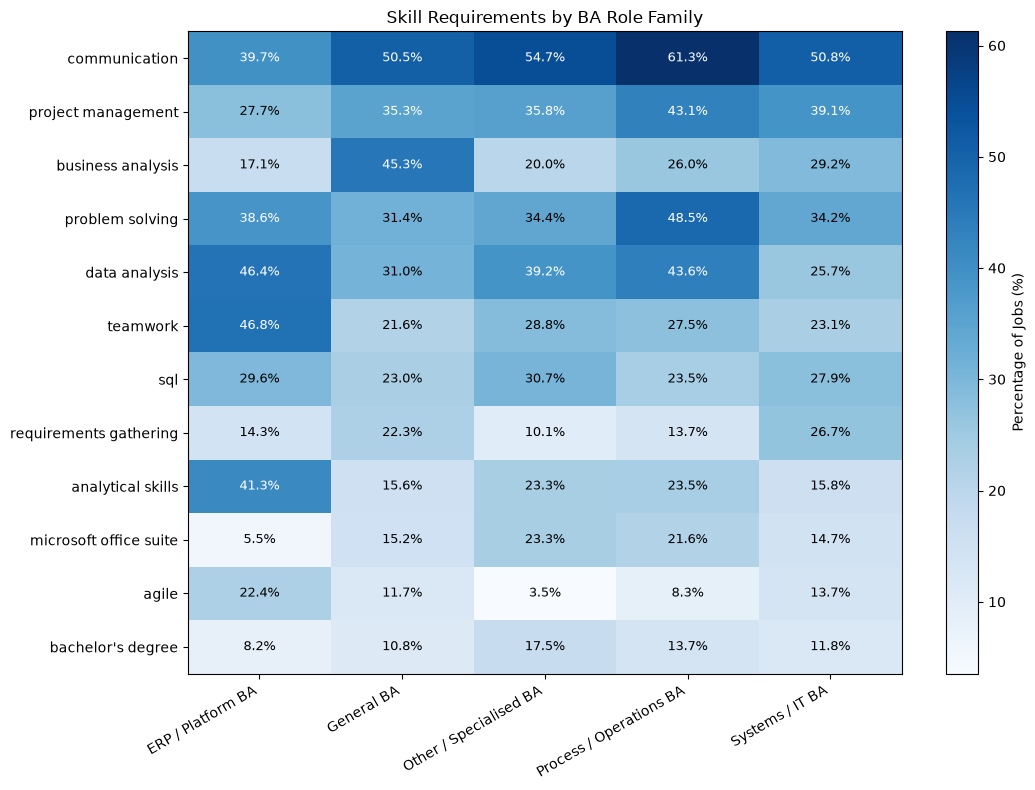

Saved: skills_by_job_role.png
Saved: skills_by_job_role.csv


In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Merge role families with cleaned skills
role_skills = skills.merge(
    ba_jobs[["job_link", "role_family"]],
    on="job_link",
    how="left",
    validate="many_to_one"
)

print("Merged rows:", len(role_skills))
print("Missing role families:",
      role_skills["role_family"].isna().sum())

# Step 2: Count jobs in each role family
role_totals = ba_jobs["role_family"].value_counts()

# Step 3: Count unique jobs mentioning each skill
role_skill_counts = (
    role_skills[
        ["job_link", "role_family", "skill_standard"]
    ]
    .drop_duplicates()
    .groupby(["skill_standard", "role_family"])["job_link"]
    .nunique()
    .unstack(fill_value=0)
)

# Step 4: Calculate percentages within each role family
role_skill_pct = (
    role_skill_counts
    .div(role_totals, axis=1)
    * 100
)

# Step 5: Select the 12 most common skills overall
top12 = (
    role_skills.groupby("skill_standard")["job_link"]
    .nunique()
    .sort_values(ascending=False)
    .head(12)
    .index
)

role_comparison = role_skill_pct.loc[top12].copy()

# Step 6: Display the comparison
print("\nSkills by Job Role (% of jobs in each family):")
display(role_comparison.round(2))

# Step 7: Create a heatmap
fig, ax = plt.subplots(figsize=(11, 8))

heatmap = ax.imshow(
    role_comparison.to_numpy(),
    cmap="Blues",
    aspect="auto"
)

ax.set_xticks(range(len(role_comparison.columns)))
ax.set_xticklabels(
    role_comparison.columns,
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(role_comparison.index)))
ax.set_yticklabels(role_comparison.index)

# Add percentage labels
for i in range(len(role_comparison.index)):
    for j in range(len(role_comparison.columns)):
        value = role_comparison.iloc[i, j]
        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > 35 else "black"
        )

ax.set_title("Skill Requirements by BA Role Family")

fig.colorbar(
    heatmap,
    ax=ax,
    label="Percentage of Jobs (%)"
)

plt.tight_layout()

# Step 8: Save chart and table
fig.savefig(
    "skills_by_job_role.png",
    dpi=300,
    bbox_inches="tight"
)

role_comparison.round(2).to_csv(
    "skills_by_job_role.csv"
)

plt.show()

print("Saved: skills_by_job_role.png")
print("Saved: skills_by_job_role.csv")


In [13]:

import pandas as pd

# Load the classified BA jobs
role_jobs = pd.read_csv("ba_jobs_with_role_family.csv")

# Check the dataset
print("Total jobs:", len(role_jobs))
print("Unique job links:", role_jobs["job_link"].nunique())

print("\nMissing values:")
print(role_jobs[["job_link", "job_title", "role_family"]].isna().sum())

print("\nRole family distribution:")
print(role_jobs["role_family"].value_counts())

# Randomly select 10 jobs from each role family
sample_jobs = (
    role_jobs.groupby("role_family", group_keys=False)
    .sample(n=10, random_state=42)
    [["job_title", "role_family"]]
    .sort_values("role_family")
    .reset_index(drop=True)
)

print("\nSample jobs for classification review:")
display(sample_jobs)

# Save the sample for manual review
sample_jobs.to_csv(
    "role_classification_validation.csv",
    index=False
)

print("\nSaved: role_classification_validation.csv")


Total jobs: 5000
Unique job links: 5000

Missing values:
job_link       0
job_title      0
role_family    0
dtype: int64

Role family distribution:
role_family
General BA                 2507
Systems / IT BA            1173
ERP / Platform BA           692
Other / Specialised BA      424
Process / Operations BA     204
Name: count, dtype: int64

Sample jobs for classification review:


,job_title,role_family
0,IT Advanced Business Analyst-Salesforce - ITS4,ERP / Platform BA
1,JDE Business Analyst (Supply Chain),ERP / Platform BA
2,JDE Business Analyst - Aerospace,ERP / Platform BA
3,"SAP Senior Business Systems Analyst , Producti...",ERP / Platform BA
4,JDE Business Analyst (Supply Chain),ERP / Platform BA
5,JDE Business Analyst (Supply Chain),ERP / Platform BA
6,HR/Workday Business Analyst,ERP / Platform BA
7,ServiceNow Business Analyst,ERP / Platform BA
8,JDE Business Analyst (Supply Chain),ERP / Platform BA
9,Workday Core HR/ Benefits Business Analyst,ERP / Platform BA



Saved: role_classification_validation.csv


In [14]:

# Check skill categories
category_counts = skills["skill_category"].value_counts()

print("Skill category distribution:")
print(category_counts)

print("\nUnclassified percentage:")
unclassified_pct = (
    skills["skill_category"].eq("Unclassified").mean() * 100
)
print(f"{unclassified_pct:.2f}%")

# Review common unclassified skills
print("\nTop 20 unclassified skills:")
display(
    skills.loc[
        skills["skill_category"] == "Unclassified"
    ]
    .groupby("skill_standard")["job_link"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
)


Skill category distribution:
skill_category
Unclassified             97731
Business / Analytical    11620
Soft / Interpersonal      8485
Technical                 4906
Other / Contextual        2552
Name: count, dtype: int64

Unclassified percentage:
78.00%

Top 20 unclassified skills:


skill_standard
project management             1776
customer service                249
powerpoint                      245
vlookups                        243
unit testing                    243
adaptability                    241
data analytics                  235
risk management                 231
integration testing             229
sap                             227
prioritization                  222
critical thinking               222
accounting                      219
data management                 219
sharepoint                      217
technical writing               216
erp systems                     216
bip output                      214
e1 interactive applications     210
data modeling                   208
Name: job_link, dtype: int64

In [15]:

# Check whether the same standardized skill
# appears in multiple categories

category_check = (
    skills.groupby("skill_standard")["skill_category"]
    .nunique()
    .sort_values(ascending=False)
)

print("Skills with multiple categories:")
print((category_check > 1).sum())

# Inspect project management specifically
print("\nProject management category distribution:")
print(
    skills.loc[
        skills["skill_standard"] == "project management",
        "skill_category"
    ].value_counts(dropna=False)
)

# Check other important skills
important_skills = [
    "communication",
    "project management",
    "business analysis",
    "data analysis",
    "sql",
    "agile"
]

print("\nCategory assignment for important skills:")
display(
    skills.loc[
        skills["skill_standard"].isin(important_skills),
        ["skill_standard", "skill_category"]
    ]
    .drop_duplicates()
    .sort_values("skill_standard")
)


Skills with multiple categories:
0

Project management category distribution:
skill_category
Unclassified    1776
Name: count, dtype: int64

Category assignment for important skills:


,skill_standard,skill_category
310,agile,Business / Analytical
12,business analysis,Business / Analytical
28,communication,Soft / Interpersonal
157,data analysis,Business / Analytical
5,project management,Unclassified
72,sql,Technical


In [16]:

# Step 1: Create a copy
skills_updated = skills.copy()

# Step 2: Define additional skill categories
category_updates = {
    "project management": "Business / Analytical",
    "customer service": "Soft / Interpersonal",
    "powerpoint": "Technical",
    "vlookups": "Technical",
    "unit testing": "Technical",
    "adaptability": "Soft / Interpersonal",
    "data analytics": "Business / Analytical",
    "risk management": "Business / Analytical",
    "integration testing": "Technical",
    "sap": "Technical",
    "critical thinking": "Soft / Interpersonal",
    "prioritization": "Soft / Interpersonal",
    "data management": "Business / Analytical",
    "accounting": "Business / Analytical",
    "sharepoint": "Technical",
    "erp systems": "Technical",
    "technical writing": "Soft / Interpersonal",
    "bip output": "Technical",
    "e1 interactive applications": "Technical",
    "data modeling": "Business / Analytical"
}

# Step 3: Update only previously unclassified skills
mask = (
    skills_updated["skill_category"].eq("Unclassified")
    & skills_updated["skill_standard"].isin(category_updates)
)

skills_updated.loc[mask, "skill_category"] = (
    skills_updated.loc[mask, "skill_standard"]
    .map(category_updates)
)

# Step 4: Compare before and after
print("Updated records:", mask.sum())

print("\nBefore:")
print(skills["skill_category"].value_counts())

print("\nAfter:")
print(skills_updated["skill_category"].value_counts())

print("\nUnclassified percentage after update:")
print(
    round(
        skills_updated["skill_category"]
        .eq("Unclassified").mean() * 100,
        2
    )
)

# Step 5: Save revised data
skills_updated.to_csv(
    "skills_competencies_updated.csv",
    index=False
)

print("\nSaved: skills_competencies_updated.csv")


Updated records: 6082

Before:
skill_category
Unclassified             97731
Business / Analytical    11620
Soft / Interpersonal      8485
Technical                 4906
Other / Contextual        2552
Name: count, dtype: int64

After:
skill_category
Unclassified             91649
Business / Analytical    14508
Soft / Interpersonal      9635
Technical                 6950
Other / Contextual        2552
Name: count, dtype: int64

Unclassified percentage after update:
73.15

Saved: skills_competencies_updated.csv


In [17]:

# Review the top 30 remaining unclassified skills

remaining = skills_updated[
    skills_updated["skill_category"] == "Unclassified"
]

top_unclassified = (
    remaining.groupby("skill_standard")["job_link"]
    .nunique()
    .sort_values(ascending=False)
    .head(30)
)

print("Top 30 remaining unclassified skills:")
print(top_unclassified)

print("\nTotal remaining unclassified records:", len(remaining))
print("Unique remaining unclassified skills:",
      remaining["skill_standard"].nunique())


Top 30 remaining unclassified skills:
skill_standard
design skills                  204
salesforce                     202
financial analysis             202
e1 batch application           197
business systems analysis      188
analytical thinking            186
erp implementation             183
erp                            183
agile methodology              182
uxone udo                      181
independent work               180
business administration        178
oracle                         177
use cases                      177
confluence                     176
systems analysis               176
as is analysis                 174
procurement                    169
data mining                    168
data extracts                  165
agile development              163
negotiation                    162
functional requirements        158
system analysis                157
inventory management           154
data loading                   154
database management systems    153
or

### Role Classification Validation

A stratified sample of 50 job titles was selected for manual review, including 10 jobs from each of the five role families.

Based on the job titles, 47 classifications appeared reasonable. Three cases required further review because their titles contained overlapping or unclear role characteristics.

The review showed that some positions could fit more than one role family. For example, Business Process Analyst (IT) includes both process and IT-related terms.

The existing classification rules were retained for this exploratory analysis. However, further validation using full job descriptions is needed.

This is a limitation of the current role classification method.